In [1]:
import ast
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter

from utils import safe_literal_eval

In [2]:
sns.set_style("white")

In [3]:
NO_TEMPORAL_INFO_MSG = 'No temporal information found'
PFIZER = 'Pfizer\\biontech'
MODERNA = 'Moderna'
JANSSEN = 'Janssen'

In [4]:
data = pd.read_csv('final_data.csv')
data.head()

,vaers_id,vax_type,vax_manu,age_yrs,sex,vax_year,num_symptoms,report_length,length_category,symptom_text,...,all_symptoms_extracted,missing_symptoms,llm_errors,num_groups,llm_result_final,issues,llm_a1_agreement,llm_a2_agreement,a1_a2_agreement,llm_final_agreement
0,1420769.0,COVID19,PFIZER\BIONTECH,59.0,F,2021,5,110,Medium,"About 4-5 days after my second dose, I began h...",...,True,NaN,NaN,4.0,"[\n {\n ""Chest pain"": [\n ""non stop c...",[],True,True,True,True
1,1527339.0,COVID19,PFIZER\BIONTECH,44.0,M,2021,7,18,Very Short,"cough, nasal congestion, runny nose, cold swea...",...,NaN,NaN,NaN,NaN,No temporal information found,[],True,True,True,True
2,1711389.0,COVID19,PFIZER\BIONTECH,NaN,F,2021,5,329,Long,right side lymph swelling; right ear pain; cou...,...,True,NaN,NaN,2.0,"[\n {\n ""Lymphadenopathy"": [\n ""lymph...","['incorrect grouping', 'llm formatting issue']",False,False,True,False
3,1021935.0,COVID19,PFIZER\BIONTECH,68.0,M,2021,5,260,Long,back pain/soreness in his lower back/had bad l...,...,True,NaN,NaN,2.0,"[\n {\n ""Vaccination site pain"": [\n ...",[],True,False,False,True
4,2749020.0,COVID19,PFIZER\BIONTECH,11.0,M,2024,7,118,Medium,The above vaccines administered without incide...,...,True,NaN,NaN,2.0,"[\n {\n ""Syncope"": [\n ""patient faint...",[],True,True,True,True


In [5]:
# data.dtypes[:15]

In [6]:
data['sex'] = data['sex'].str.strip()
data['vax_type'] = data['vax_type'].str.strip()
data['symptom_text'] = data['symptom_text'].str.strip()
data['length_category'] = data['length_category'].str.strip()
data['vax_manu'] = data['vax_manu'].str.strip().str.capitalize()

data['issues'] = data['issues'].apply(ast.literal_eval)
data['symptom_list'] = data['symptom_list'].apply(ast.literal_eval)
data['llm_result_final'] = data['llm_result_final'].apply(safe_literal_eval)
data['final_corrected_version'] = data['final_corrected_version'].apply(safe_literal_eval)

data['has_temporal_info'] = data['llm_result_final'].apply(lambda x: x != NO_TEMPORAL_INFO_MSG)

Could not parse string: [
  {
    "Dry mouth": [
      "Dry mouth"
    ],
    "Taste disorder": [
      "metal taste"
    ]
  },
  {
    "Headache": [
      "Headache one hour after"
    ]
  }, {
    "Pruritus": [
      "Itchy started a few hours after especially on hands"
    ]
  },
  {
    "Abdominal discomfort": [
      "Upset stomach a few hours after"
    ]
  }
  {
    "Pyrexia": [
      "Fever the next day"
    ],
    "Depression": [
      "Severe depression"
    ],
    "Suicidal ideation": [
      "suicidal thoughts"
    ]
  }
]. Exception: invalid syntax. Perhaps you forgot a comma? (<unknown>, line 19)


In [7]:
data.has_temporal_info.value_counts()

has_temporal_info
True     3819
False    2181
Name: count, dtype: int64

In [8]:
data.columns

Index(['vaers_id', 'vax_type', 'vax_manu', 'age_yrs', 'sex', 'vax_year',
       'num_symptoms', 'report_length', 'length_category', 'symptom_text',
       'symptom_list', 'llm_result', 'llm_result_formatted', 't_result',
       't_corrected_version', 't_category', 't_notes', 'h_result',
       'h_corrected_version', 'h_notes', 'final_result',
       'final_corrected_version', 'final_notes', 'all_symptoms_extracted',
       'missing_symptoms', 'llm_errors', 'num_groups', 'llm_result_final',
       'issues', 'llm_a1_agreement', 'llm_a2_agreement', 'a1_a2_agreement',
       'llm_final_agreement', 'has_temporal_info'],
      dtype='object')

In [9]:
no_temporal_records = data.query('llm_result_final == "No temporal information found"')
uncertain_records = data.query('final_result == 2')
incorrect_records = data.query('final_result == 0')
data_to_analyze = data.query('final_result != 2 and llm_result_final != "No temporal information found"')
data_to_analyze.shape

(3166, 34)

In [10]:
no_temporal_records.shape, uncertain_records.shape, incorrect_records.shape, data_to_analyze.shape

((2181, 34), (653, 34), (559, 34), (3166, 34))

## Exploratory Data Analysis:

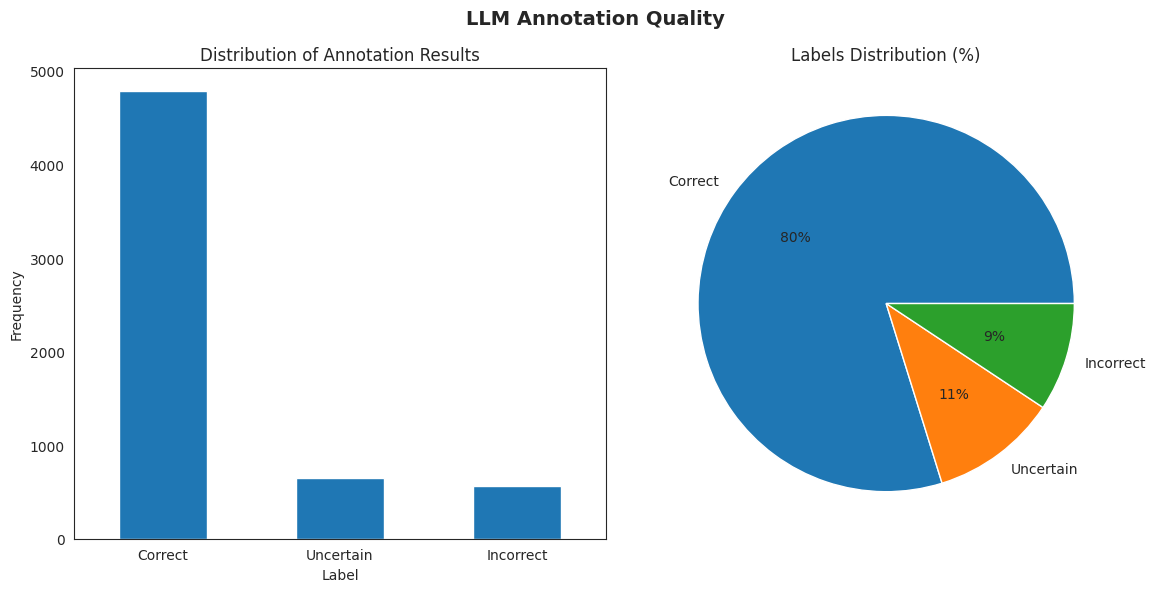

In [11]:
# Map values to labels and get counts
labeled_counts = data.final_result.map({ 0: 'Incorrect', 1: 'Correct', 2: 'Uncertain'}).value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

labeled_counts.plot.bar(ax=ax1)
ax1.set_xlabel('Label')
ax1.set_ylabel('Frequency')
ax1.tick_params(axis='x', rotation=0)
ax1.set_title('Distribution of Annotation Results')

# Pie chart on right
labeled_counts.plot.pie(autopct='%1.0f%%', ax=ax2)
ax2.set_ylabel('')
ax2.set_title('Labels Distribution (%)')

fig.suptitle('LLM Annotation Quality', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [12]:
def plot_agreement_rate(data):
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    agreement_mapping = {True: 'Agree', False: 'Disagree'}
    llm_a1_agreement = data.llm_a1_agreement.map(agreement_mapping).value_counts()
    llm_a1_agreement.plot.pie(autopct='%1.0f%%', ax=axs[0, 0])
    axs[0, 0].set_title('LLM-Annotator 1 Concordance')

    llm_a2_agreement = data.llm_a2_agreement.map(agreement_mapping).value_counts()
    llm_a2_agreement.plot.pie(autopct='%1.0f%%', ax=axs[0, 1])
    axs[0, 1].set_title('LLM-Annotator 2 Concordance')

    a1_a2_agreement = data.a1_a2_agreement.map(agreement_mapping).value_counts()
    a1_a2_agreement.plot.pie(autopct='%1.0f%%', ax=axs[1, 0])
    axs[1, 0].set_title('Inter-Annotator Agreement (A1 vs A2)')

    llm_final_agreement = data.llm_final_agreement.map(agreement_mapping).value_counts()
    llm_final_agreement.plot.pie(autopct='%1.0f%%', ax=axs[1, 1])
    axs[1, 1].set_title('LLM-Ground Truth Alignment')

    for ax in axs.flatten():
        ax.set_ylabel('')  # Remove the y-label that pie charts often have

    fig.suptitle('Inter-Rater Agreement Analysis: LLM vs Human Annotators', fontsize=14,  fontweight='bold')
    plt.tight_layout()
    plt.show()

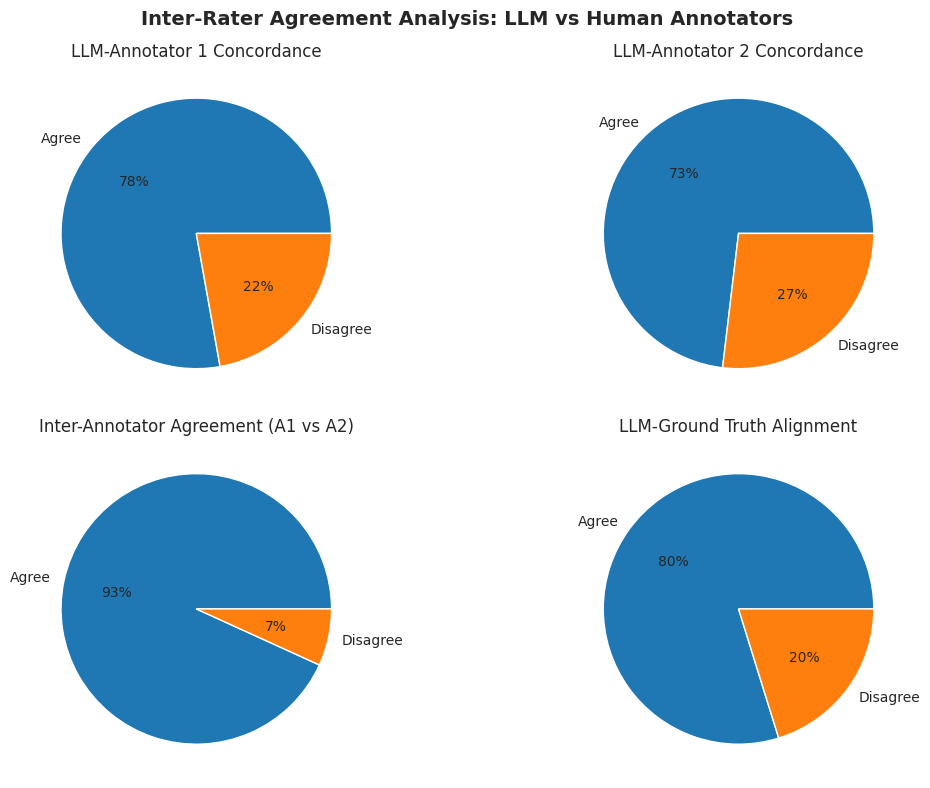

In [13]:
plot_agreement_rate(data)

In [14]:
def get_data_issues(data):
    #Create a flat list of all issues
    all_issues = []
    for issues_list in data['issues']:
        all_issues.extend(issues_list)

    # Count frequency of each issue and get top 10
    return Counter(all_issues)


def get_symptoms_count(data, index=0):
    """

    :param data: Dataframe with columns llm_result_final
    :param index: 0 for first group, -1 for last group
    :return:
    """

    symptoms = []
    for record in data.itertuples():
        try:
            if isinstance(record.llm_result_final, list):
                # ordered_symptoms_list = ast.literal_eval(record.llm_result_final)
                symptoms.extend(list(record.llm_result_final[index].keys()))

        except Exception as e:
            print(record.vaers_id, e)

    symptoms_count = Counter(symptoms)
    return symptoms_count


def get_symptoms_with_no_original_mention(data):

    symptoms_with_no_mention = []
    for record in data.itertuples():
        try:
            if isinstance(record.llm_result_final, str):
                ordered_symptoms_list = ast.literal_eval(record.llm_result_final)
                last_group = ordered_symptoms_list[-1]

                if any(value == ["none"] for value in list(last_group.values())):
                    symptoms_with_no_mention.extend(list(last_group.keys()))

        except Exception as e:
            print(record.vaers_id, e)

    symptoms_with_no_mention = Counter(symptoms_with_no_mention)
    return symptoms_with_no_mention


def get_symptoms_with_missing_original_mention(data):

    all_symptoms_with_missing_mention = []

    for record in data.itertuples():
        try:
            if isinstance(record.llm_result_formatted, str):
                initial_symptoms_list = ast.literal_eval(record.llm_result_formatted)
                initial_symptoms_without_mention = []

                if any(value == ["none"] for value in initial_symptoms_list[-1].values()):
                    initial_symptoms_without_mention = list(initial_symptoms_list[-1].keys())

                if isinstance(record.llm_result_final, str):
                    final_symptoms_list = ast.literal_eval(record.llm_result_final)
                    final_symptoms_without_mention = []

                    if any(value == ["none"] for value in final_symptoms_list[-1].values()):
                        final_symptoms_without_mention = list(final_symptoms_list[-1].keys())

                    symptoms_with_missing_mention = set(initial_symptoms_without_mention) - set(final_symptoms_without_mention)
                    all_symptoms_with_missing_mention.extend(list(symptoms_with_missing_mention))

        except Exception as e:
            print(record.vaers_id, e, record.llm_result_formatted, record.llm_result_final)

    symptoms_with_missing_mention = Counter(all_symptoms_with_missing_mention)
    return symptoms_with_missing_mention


def plot_top(counter, text='Symptoms'):

    top_10 = counter.most_common(10)

    # Create DataFrame for plotting
    top_10_df = pd.DataFrame(top_10, columns=[text, 'Count'])

    # Plotting
    plt.figure(figsize=(12, 8))

    # Create horizontal bar plot (easier to read long issue names)
    plt.subplot(1, 2, 1)
    bars = plt.barh(top_10_df[text], top_10_df['Count'])
    plt.xlabel('Frequency')
    plt.title(f'Top 10 Most Common {text.title()}')
    plt.gca().invert_yaxis()  # Highest count at top

    # Add value labels on bars
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
                 f'{int(width)}', ha='left', va='center')

    # Create pie chart for proportion view
    plt.subplot(1, 2, 2)
    plt.pie(top_10_df['Count'], labels=top_10_df[text], autopct='%1.1f%%', startangle=90)
    plt.title(f'Proportion of Top 10 {text.title()}')

    plt.tight_layout()
    plt.show()

    # Print the top 10 issues for reference
    # print(f"\nTop 10 {text.title()}:")
    # for i, (text, count) in enumerate(top_10, 1):
    #     print(f"{i}. {text}: {count} occurrences")

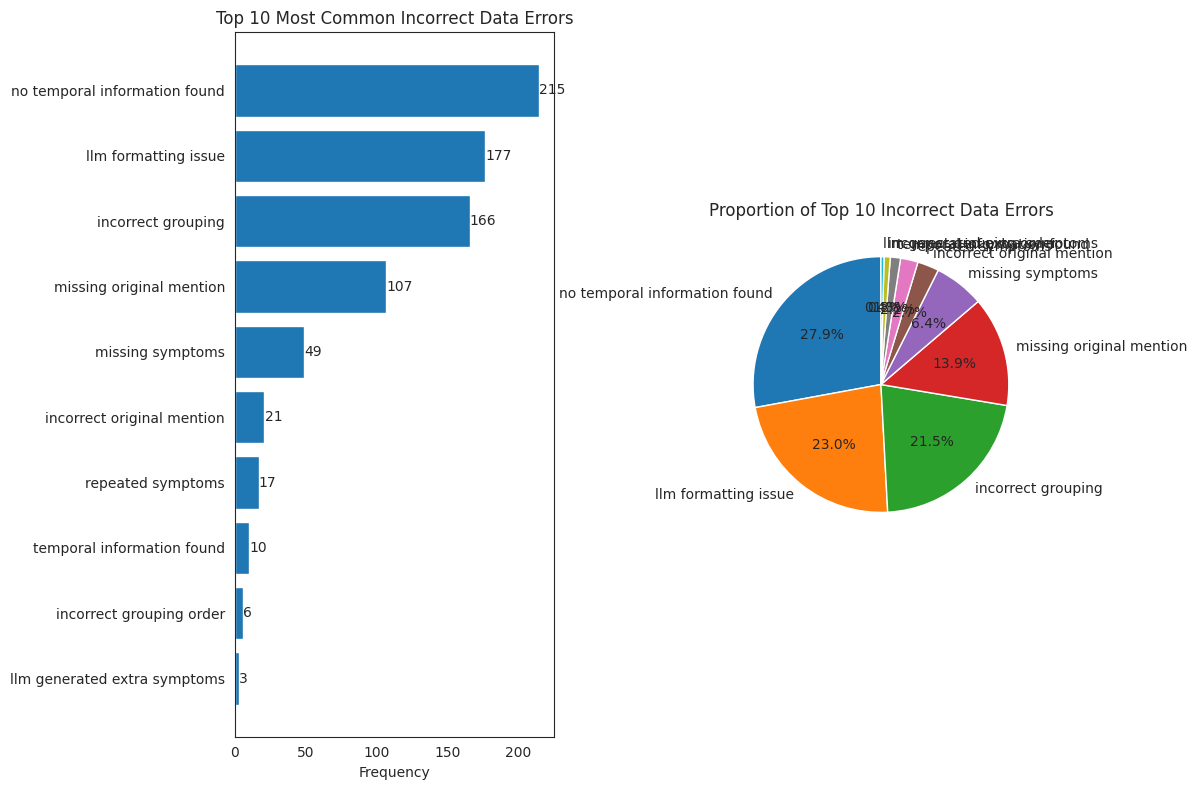

In [15]:
incorrect_data_errors = get_data_issues(incorrect_records)
plot_top(incorrect_data_errors, 'Incorrect Data Errors')

In [16]:
# uncertain_data_errors

/tmp/ipykernel_22817/4240336693.py:110: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


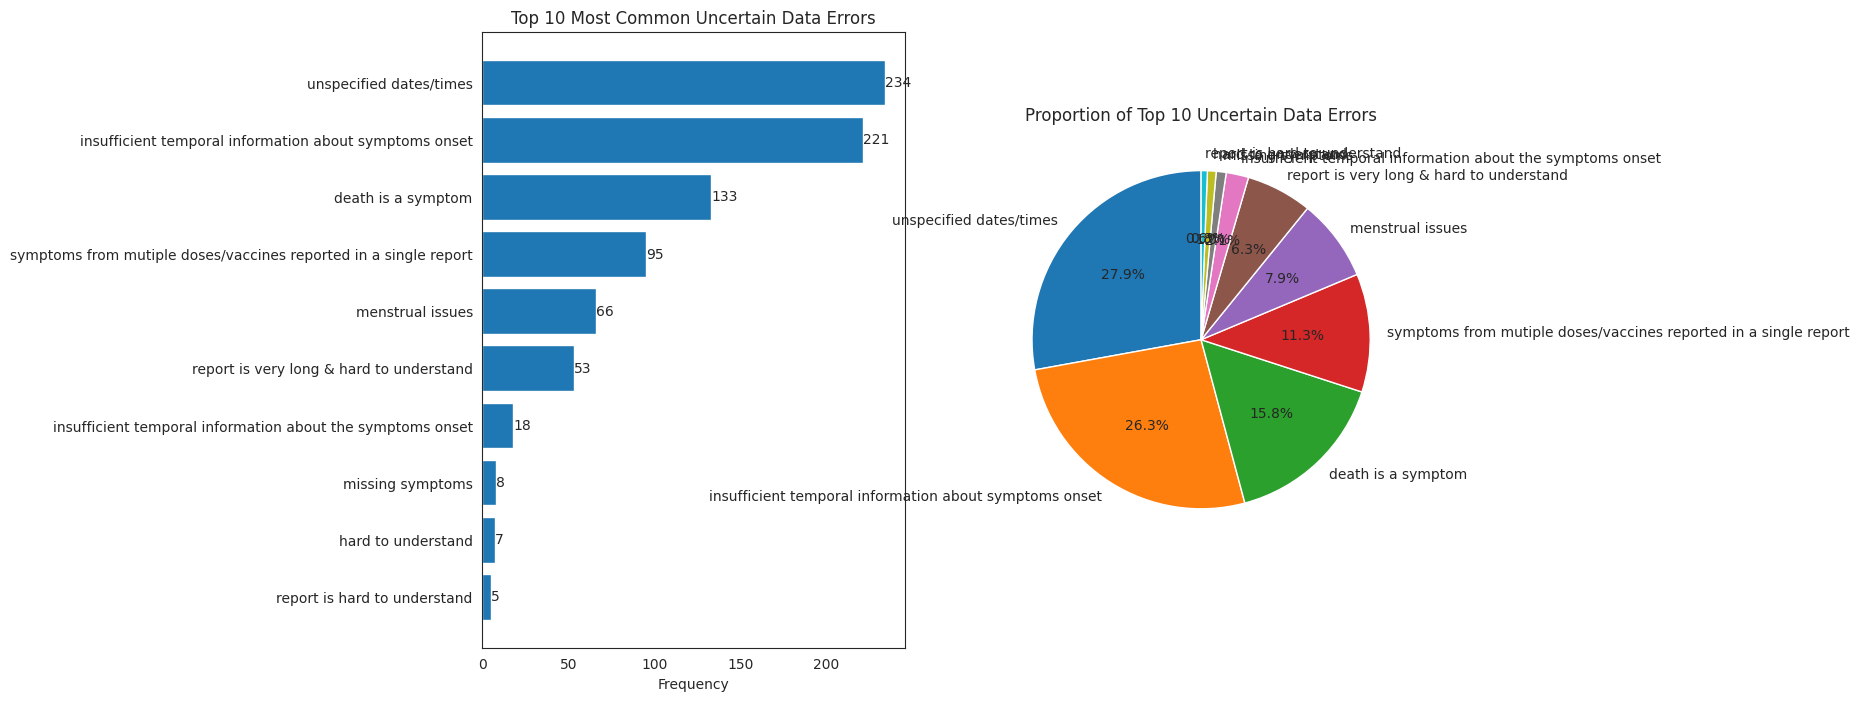

In [17]:
uncertain_data_errors = get_data_issues(uncertain_records)
plot_top(uncertain_data_errors, 'Uncertain Data Errors')

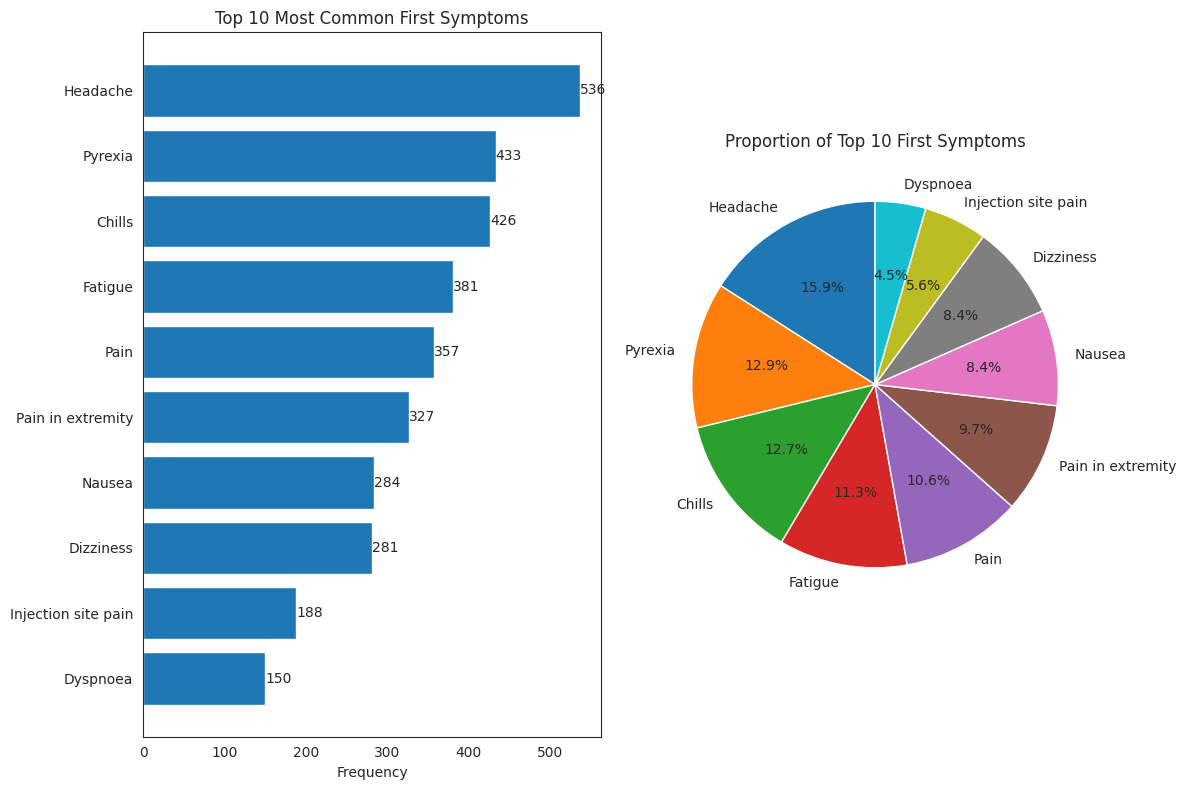

In [18]:
first_group_symptoms = get_symptoms_count(data_to_analyze, index=0)
plot_top(first_group_symptoms, text='First Symptoms')

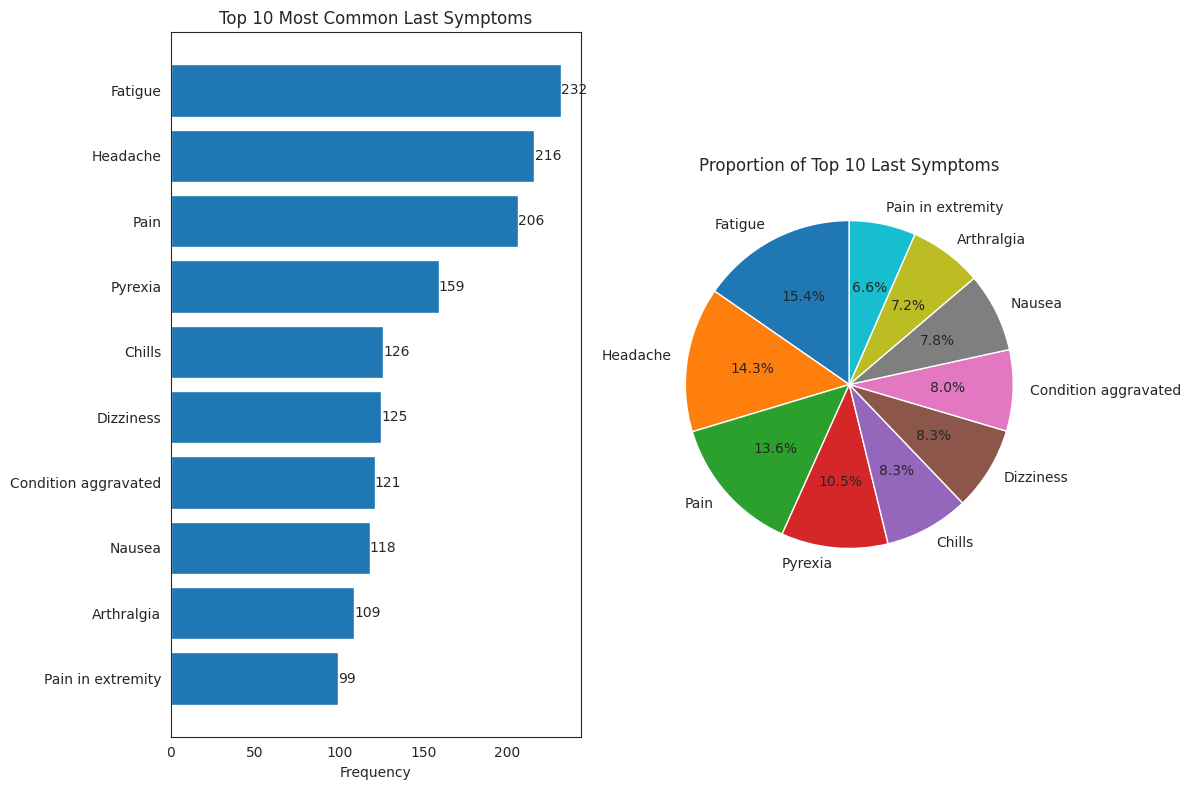

In [19]:
last_group_symptoms = get_symptoms_count(data_to_analyze, index=-1)
plot_top(last_group_symptoms, text='Last Symptoms')

In [20]:
# symptoms_with_missing_mention = get_symptoms_with_missing_original_mention(data_to_analyze)
# plot_top(symptoms_with_missing_mention, text='Symptoms with Missing Original Mention')

In [21]:
# symptoms_with_no_mention = get_symptoms_with_no_original_mention(data_to_analyze)
# plot_top(symptoms_with_no_mention, text='Symptoms With No  Original Mention')

## Analysis of Records with no uncertain values:

In [22]:
data_to_analyze = data.query('final_result != 2')
data_to_analyze.shape

(5347, 34)

In [23]:
# Add this after the cell where you load and parse the data (after cell 18)

def calculate_temporal_groups(llm_result):
    """
    Calculate number of temporal groups from llm_result_final.
    Returns 0 if no temporal information found.
    Subtracts 1 if last group contains 'none' values.
    """
    if llm_result == NO_TEMPORAL_INFO_MSG: # or pd.isna(llm_result):
        return 1
    
    try:
        if isinstance(llm_result, str):
            groups = ast.literal_eval(llm_result)
        else:
            groups = llm_result
            
        if not groups or len(groups) == 0:
            return 0
            
        # Check if last group has 'none' values
        last_group = groups[-1]
        has_none = any(
            value == ["none"] or value == "none" 
            for value in last_group.values()
        )
        
        # Return length minus 1 if last group has none, otherwise just length
        return len(groups) - 1 if has_none else len(groups)
        
    except Exception as e:
        print(f"Error parsing: {e}")
        return 0
    
def create_summary(data):
    # Group by vaccine manufacturer
    summary = data.groupby('vax_manu').agg(
        num_reports=('vax_manu', 'count'),
        avg_length=('report_length', 'mean'),
        median_length=('report_length', 'median'),
        min_length=('report_length', 'min'),
        max_length=('report_length', 'max'),
        avg_symptoms=('num_symptoms', 'mean'),
        median_symptoms=('num_symptoms', 'median'),
        min_symptoms=('num_symptoms', 'min'),
        max_symptoms=('num_symptoms', 'max'),
        avg_timesteps=('num_temporal_groups', 'mean'),
        median_timesteps=('num_temporal_groups', 'median'),
        min_timesteps=('num_temporal_groups', 'min'),
        max_timesteps=('num_temporal_groups', 'max')
    ).reset_index()

    # Rename columns for clarity
    summary.rename(columns={
        'vax_manu': 'Vaccine Manufacturer',
        'num_reports': '# of Reports',
        'avg_length': 'Average Length',
        'median_length': 'Median Length',
        'min_length': 'Min Length',
        'max_length': 'Max Length',
        'avg_symptoms': 'Average # Symptoms',
        'median_symptoms': 'Median # Symptoms',
        'min_symptoms': 'Min # Symptoms',
        'max_symptoms': 'Max # Symptoms',
        'avg_timesteps': 'Average # Timesteps',
        'median_timesteps': 'Median # Timesteps',
        'min_timesteps': 'Min # Timesteps',
        'max_timesteps': 'Max # Timesteps'
    }, inplace=True)

    return summary

def get_llm_result_without_none_symptoms(llm_result):

    temporal_list = []
    try:
        if any(value in ["none", ["none"]] for value in llm_result[-1].values()):
            llm_result = llm_result[:-1]
        for temp_group in llm_result:
            temporal_list.append(list(temp_group.keys()))
        return temporal_list
    except:
        print('Error occurred while parsing llm_result_final')

In [24]:
# Add the new column
data_to_analyze['num_temporal_groups'] = data_to_analyze['llm_result_final'].apply(calculate_temporal_groups)
temporal_data = data_to_analyze.query(f'llm_result_final != "{NO_TEMPORAL_INFO_MSG}"')
no_temporal_data = data_to_analyze.query(f'llm_result_final == "{NO_TEMPORAL_INFO_MSG}"')
# # Verify the results
# print("Temporal groups distribution:")
# print(data_to_analyze['num_temporal_groups'].value_counts().sort_index())
# print(f"\nSummary statistics:")
# print(data_to_analyze['num_temporal_groups'].describe())

/tmp/ipykernel_22817/1530091430.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_to_analyze['num_temporal_groups'] = data_to_analyze['llm_result_final'].apply(calculate_temporal_groups)


In [25]:
final_data_summary = create_summary(data_to_analyze)
temporal_data_summary = create_summary(temporal_data)
no_temporal_data_summary = create_summary(no_temporal_data)

In [26]:
final_data_summary.head()

,Vaccine Manufacturer,# of Reports,Average Length,Median Length,Min Length,Max Length,Average # Symptoms,Median # Symptoms,Min # Symptoms,Max # Symptoms,Average # Timesteps,Median # Timesteps,Min # Timesteps,Max # Timesteps
0,Janssen,1789,120.185020,87.0,11,1317,7.046395,6.0,4,43,2.462828,2.0,1,13
1,Moderna,1769,131.335783,83.0,11,1056,6.504240,6.0,4,30,2.111928,2.0,1,9
2,Pfizer\biontech,1789,167.134153,102.0,11,2319,6.604248,6.0,4,64,2.198994,2.0,1,10


In [27]:
no_temporal_data_summary.head()

,Vaccine Manufacturer,# of Reports,Average Length,Median Length,Min Length,Max Length,Average # Symptoms,Median # Symptoms,Min # Symptoms,Max # Symptoms,Average # Timesteps,Median # Timesteps,Min # Timesteps,Max # Timesteps
0,Janssen,625,93.409600,56.0,11,1317,6.150400,5.0,4,33,1.0,1.0,1,1
1,Moderna,786,119.020356,57.0,11,1056,5.921120,5.0,4,29,1.0,1.0,1,1
2,Pfizer\biontech,770,153.263636,80.5,11,2319,6.163636,5.0,4,64,1.0,1.0,1,1


# Temporal Data Analysis:

In [28]:
temporal_data_summary.head()

,Vaccine Manufacturer,# of Reports,Average Length,Median Length,Min Length,Max Length,Average # Symptoms,Median # Symptoms,Min # Symptoms,Max # Symptoms,Average # Timesteps,Median # Timesteps,Min # Timesteps,Max # Timesteps
0,Janssen,1164,134.561856,100.0,12,826,7.527491,7.0,4,43,3.248282,3.0,2,13
1,Moderna,983,141.183113,99.0,13,905,6.970498,6.0,4,30,3.001017,3.0,2,9
2,Pfizer\biontech,1019,177.615309,109.0,12,1638,6.937193,6.0,4,29,3.105005,3.0,1,10


In [29]:
temporal_data['indexed_symptoms'] = temporal_data['llm_result_final'].apply(get_llm_result_without_none_symptoms)

/tmp/ipykernel_22817/1592638208.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temporal_data['indexed_symptoms'] = temporal_data['llm_result_final'].apply(get_llm_result_without_none_symptoms)


### Agreement Rate Calculation for Temporal Data

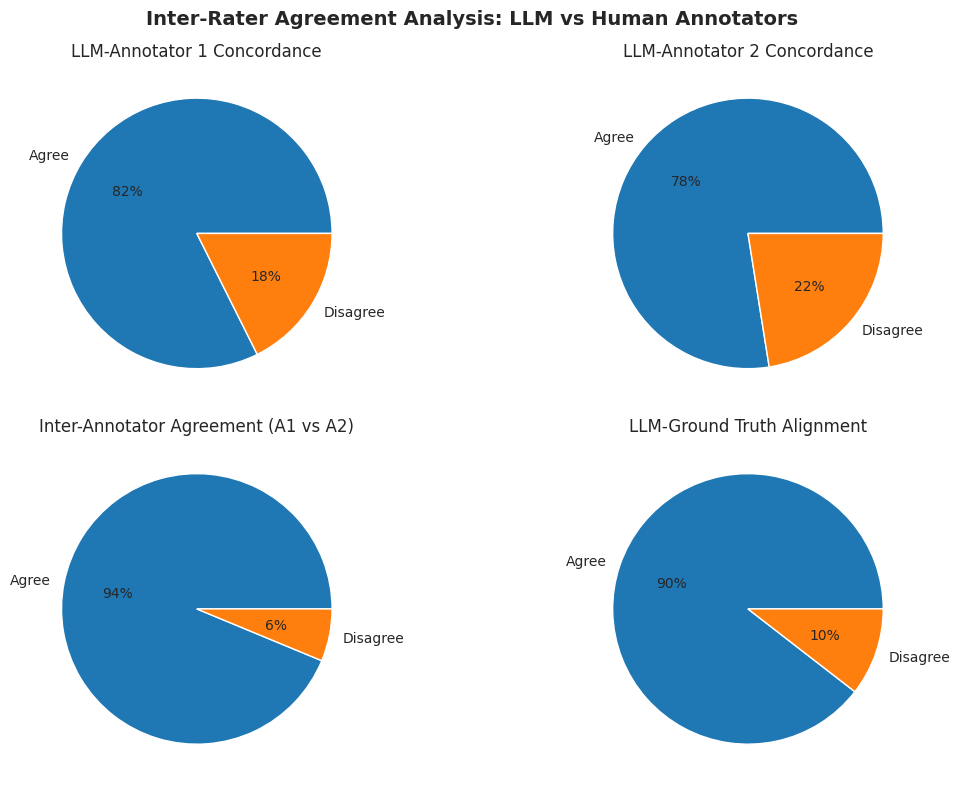

In [30]:
plot_agreement_rate(temporal_data)

In [31]:
def get_symptom_counts(df, manufacturer=None):
    if manufacturer:
        df = df[df['vax_manu'] == manufacturer]
    symptoms = [symptom for sublist in df['indexed_symptoms'] for group in sublist for symptom in group]
    return Counter(symptoms)
 
def get_kth_symptom_counts(df, manufacturer=None, k=0):
    if manufacturer:
        df = df[df['vax_manu'] == manufacturer]
    symptoms = [symptom for sublist in df['indexed_symptoms'] if len(sublist) > k for symptom in sublist[k]]
    return Counter(symptoms)

def get_top_frequent_symptoms(df, n=5, manufacturer=None):
    first_symptoms = get_symptom_counts(df, manufacturer)
    return [symptom for symptom, _ in Counter(first_symptoms).most_common(n)]

def get_top_first_symptoms(df, n=5, manufacturer=None):
    first_symptoms = get_kth_symptom_counts(df, manufacturer, k=0)
    return [symptom for symptom, _ in Counter(first_symptoms).most_common(n)]

def get_top_second_symptoms(df, first_symptom, manufacturer=None, n=5):
    if manufacturer:
        df = df[df['vax_manu'] == manufacturer]
    second_symptoms = [
        symptom for sublist in df['indexed_symptoms'] 
        if len(sublist) > 1 and first_symptom in sublist[0]
        for symptom in sublist[1] 
    ]
    return Counter(second_symptoms).most_common(n)

def get_top_coocurring_symptoms(df, first_symptom, manufacturer=None, n=5):
    if manufacturer:
        df = df[df['vax_manu'] == manufacturer]
    cooccurring_symptoms = [
        symptom 
        for sublist in df['indexed_symptoms'] 
        for group in sublist
        for symptom in group 
        if first_symptom in group and symptom != first_symptom
    ]
    return Counter(cooccurring_symptoms).most_common(n)

def get_top_after_symptoms(df, first_symptom, manufacturer=None, n=5):
    if manufacturer:
        df = df[df['vax_manu'] == manufacturer]
    after_symptoms = [
        symptom 
        for sublist in df['indexed_symptoms'] 
        for i, group in enumerate(sublist)
        if first_symptom in group
        for later_group in sublist[i+1:]
        for symptom in later_group
    ]
    return Counter(after_symptoms).most_common(n)

def build_overall_comparison_df(
    data,
    manufacturers,
    count_fn,          # function to compute counts
    n_top=10,
    n_overall=15,
):
    """
    Builds a comparison DataFrame with columns:
    Symptom | <Manufacturer 1> | <Manufacturer 2> | ... | Overall
    """

    # Top-N per manufacturer
    top_by_manu = {
        manu: count_fn(data, manu).most_common(n_top)
        for manu in manufacturers
    }

    # Top-N overall
    top_overall = count_fn(data).most_common(n_overall)

    # Base DataFrame
    df = pd.DataFrame(top_overall, columns=["Symptom", "Count"])

    # Add manufacturer-specific columns
    for manu in manufacturers:
        manu_counts = dict(top_by_manu[manu])
        df[manu] = df["Symptom"].map(manu_counts).fillna(0)

    # Add overall column
    df["Overall"] = df["Count"]

    return df


In [32]:
# # Get top 10 symptoms for each manufacturer and overall
n_top = 10
n_overall = 15
manufacturers = [PFIZER, MODERNA, JANSSEN]
top10_by_manu = {manu: get_symptom_counts(temporal_data, manu).most_common(n_top) for manu in manufacturers}
top10_1st_by_manu = {manu: get_kth_symptom_counts(temporal_data, manu).most_common(n_top) for manu in manufacturers}

overall_df = build_overall_comparison_df(
    data=temporal_data,
    manufacturers=manufacturers,
    count_fn=get_symptom_counts,
    n_top=10,
    n_overall=15,
)

overall_1st_df = build_overall_comparison_df(
    data=temporal_data,
    manufacturers=manufacturers,
    count_fn=get_kth_symptom_counts,
    n_top=10,
    n_overall=15,
)


In [33]:
overall_df

,Symptom,Count,Pfizer\biontech,Moderna,Janssen,Overall
0,Headache,1059,300.0,295.0,464.0,1059
1,Fatigue,889,257.0,291.0,341.0,889
2,Pyrexia,864,248.0,264.0,352.0,864
3,Chills,777,195.0,245.0,337.0,777
4,Pain,713,200.0,212.0,301.0,713
5,Nausea,631,192.0,162.0,277.0,631
6,Dizziness,586,194.0,131.0,261.0,586
7,Pain in extremity,566,169.0,196.0,201.0,566
8,Dyspnoea,390,119.0,104.0,167.0,390
9,Myalgia,303,0.0,0.0,0.0,303


In [34]:
overall_1st_df

,Symptom,Count,Pfizer\biontech,Moderna,Janssen,Overall
0,Headache,536,147.0,155.0,234.0,536
1,Pyrexia,433,116.0,137.0,180.0,433
2,Chills,426,96.0,133.0,197.0,426
3,Fatigue,381,105.0,142.0,134.0,381
4,Pain,357,96.0,108.0,153.0,357
5,Pain in extremity,327,104.0,127.0,96.0,327
6,Nausea,284,75.0,78.0,131.0,284
7,Dizziness,281,96.0,64.0,121.0,281
8,Injection site pain,188,0.0,71.0,75.0,188
9,Dyspnoea,150,51.0,0.0,0.0,150


In [35]:
set(overall_1st_df.Symptom.to_list())

{'Arthralgia',
 'Asthenia',
 'Chills',
 'Cough',
 'Dizziness',
 'Dyspnoea',
 'Fatigue',
 'Headache',
 'Injection site pain',
 'Malaise',
 'Myalgia',
 'Nausea',
 'Pain',
 'Pain in extremity',
 'Pyrexia'}

In [36]:
set(overall_df.Symptom.to_list())

{'Arthralgia',
 'Asthenia',
 'Chills',
 'Dizziness',
 'Dyspnoea',
 'Fatigue',
 'Headache',
 'Hyperhidrosis',
 'Injection site pain',
 'Myalgia',
 'Nausea',
 'Pain',
 'Pain in extremity',
 'Pyrexia',
 'Vomiting'}

In [37]:
def plot_top10_symptoms_grid(
    top10_by_manu_dict,
    overall_df,
    manufacturers,                      # e.g. [PFIZER, MODERNA, JANSSEN]
    overall_col="Overall",              # name of overall column in overall_df
    is_first_reported=False,            # True -> "First-Reported", False -> "Reported"
    palettes=("Blues_d", "Greens_d", "Reds_d"),
    # palettes=("Greys", "Greys_r", "dark:grey"),
    figsize=(20, 4), #(16, 12)
):
    """
    ACL-targeted 2x2 grid:
      (A) Most frequent adverse events for manu[0]
      (B) Most frequent adverse events for manu[1]
      (C) Most frequent adverse events for manu[2]
      (D) Cross-manufacturer comparison (incl. Overall)
    """

    # ACL-style phrasing
    event_phrase = "First-Reported Adverse Event" if is_first_reported else "Reported Adverse Events"
    x_label = "Number of VAERS Reports"
    y_label = "Adverse Event (MedDRA Term)"
    legend_title = "Vaccine Manufacturer"
    x_lim = 500 if not is_first_reported else 250

    fig, axes = plt.subplots(1, 4, figsize=figsize)
    axes = axes.flatten()


    panel_labels = ["(A)", "(B)", "(C)"]

    # --- First 3 subplots: per-manufacturer top 10 ---
    for i, manu in enumerate(manufacturers[:3]):
        data = top10_by_manu_dict[manu]   # list of (symptom, count)
        symptoms = [s for s, _ in data]
        counts   = [c for _, c in data]

        # IMPORTANT: do NOT use hue=symptoms here (it creates an unnecessary legend)
        sns.barplot(x=counts, y=symptoms, hue=symptoms, ax=axes[i], palette=palettes[i], legend=False)
        axes[i].set_title(f"{panel_labels[i]} Most Frequent {event_phrase} — {manu}")
        axes[i].set_xlim(0, x_lim)
        axes[i].set_xlabel(x_label)
        axes[i].set_ylabel(y_label)

    # --- 4th subplot: overall melted ---
    value_vars = [*manufacturers[:3], overall_col]
    overall_melted = overall_df.melt(
        id_vars=["Symptom"],
        value_vars=value_vars,
        var_name=legend_title,
        value_name="Number of VAERS Reports",
    )

    sns.barplot(
        data=overall_melted,
        x="Number of VAERS Reports",
        y="Symptom",
        hue=legend_title,
        ax=axes[3],
    )
    axes[3].set_title(f"(D) Cross-Manufacturer Comparison of {event_phrase}")
    axes[3].set_xlabel(x_label)
    axes[3].set_ylabel(y_label)

    # Make legend title ACL-clean
    axes[3].legend(loc="best")

    plt.tight_layout()
    plt.show()

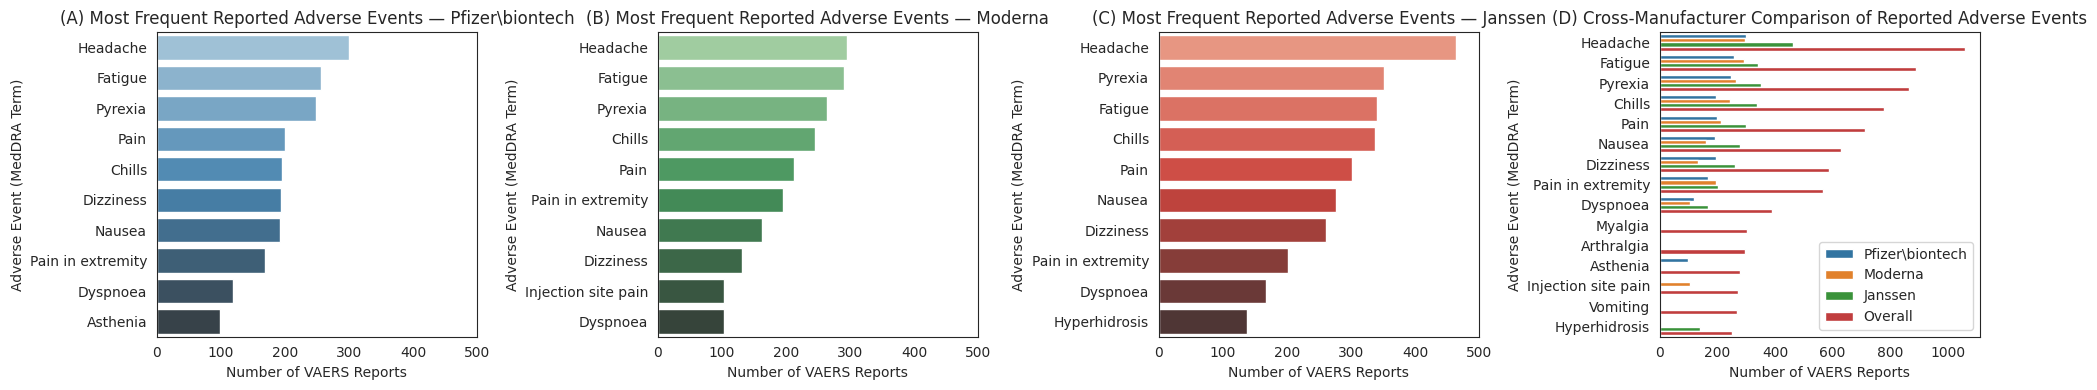

In [38]:
# Case 1: Any mention / overall frequency
plot_top10_symptoms_grid(
    top10_by_manu_dict=top10_by_manu,
    overall_df=overall_df,
    manufacturers=[PFIZER, MODERNA, JANSSEN],
    is_first_reported=False,
)

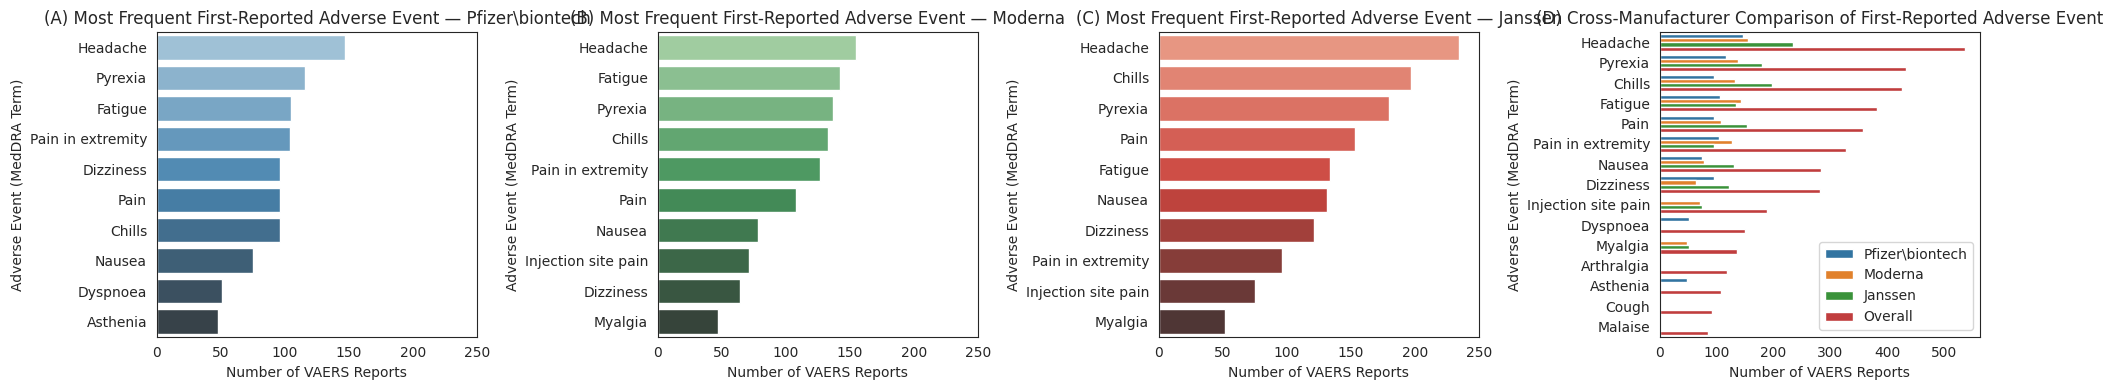

In [39]:
# Case 2: First-reported symptom/event
plot_top10_symptoms_grid(
    top10_by_manu_dict=top10_1st_by_manu,
    overall_df=overall_1st_df,
    manufacturers=[PFIZER, MODERNA, JANSSEN],
    is_first_reported=True,
)

In [40]:
def plot_top10_symptoms_per_manufacturer_panels(
    top10_by_manu_dict,
    manufacturers,                      # e.g. ["PFIZER", "MODERNA", "JANSSEN"]
    is_first_reported=False,
    palettes=("Blues_d", "Greens_d", "Reds_d"),
    figsize=(15, 4),
    xlim=(0, 500),
):
    """
    1x3 grid: Top 10 symptoms for each manufacturer (A/B/C).
    Keeps subplots together. Titles are optional; currently kept as panel labels.
    """

    event_phrase = "First-Reported Adverse Event" if is_first_reported else "Reported Adverse Events"
    x_label = "Number of VAERS Reports"
    y_label = "Adverse Event (MedDRA Term)"
    panel_labels = ["(A)", "(B)", "(C)"]

    fig, axes = plt.subplots(1, 3, figsize=figsize)
    axes = axes.flatten()

    for i, manu in enumerate(manufacturers[:3]):
        data = top10_by_manu_dict[manu]   # list of (symptom, count)
        symptoms = [s for s, _ in data]
        counts   = [c for _, c in data]

        sns.barplot(
            x=counts,
            y=symptoms,
            hue=symptoms,
            ax=axes[i],
            palette=palettes[i]
        )

        axes[i].set_title(f"{panel_labels[i]} Most Frequent {event_phrase} — {manu}")
        axes[i].set_xlim(*xlim)
        axes[i].set_xlabel(x_label)
        axes[i].set_ylabel(y_label)

    plt.tight_layout()
    plt.show()


def plot_top10_symptoms_consolidated_ax(
    overall_df,
    manufacturers,
    overall_col="Overall",
    legend_title="Vaccine Manufacturer",
    xlim=(0, 1100),
    ax=None,
):
    """
    Draws a consolidated top-10 symptoms plot on a given matplotlib axis.
    (No title, suitable for side-by-side panels)
    """

    x_label = "Number of VAERS Reports"
    y_label = "Adverse Event (MedDRA Term)"

    value_vars = [*manufacturers[:3], overall_col]
    overall_melted = overall_df.melt(
        id_vars=["Symptom"],
        value_vars=value_vars,
        var_name=legend_title,
        value_name="Number of VAERS Reports",
    )

    sns.barplot(
        data=overall_melted,
        x="Number of VAERS Reports",
        y="Symptom",
        hue=legend_title,
        ax=ax,
    )

    ax.set_xlim(*xlim)
    ax.set_xlabel(x_label)
    # ax.set_ylabel(y_label)
    ax.legend(loc="lower right")


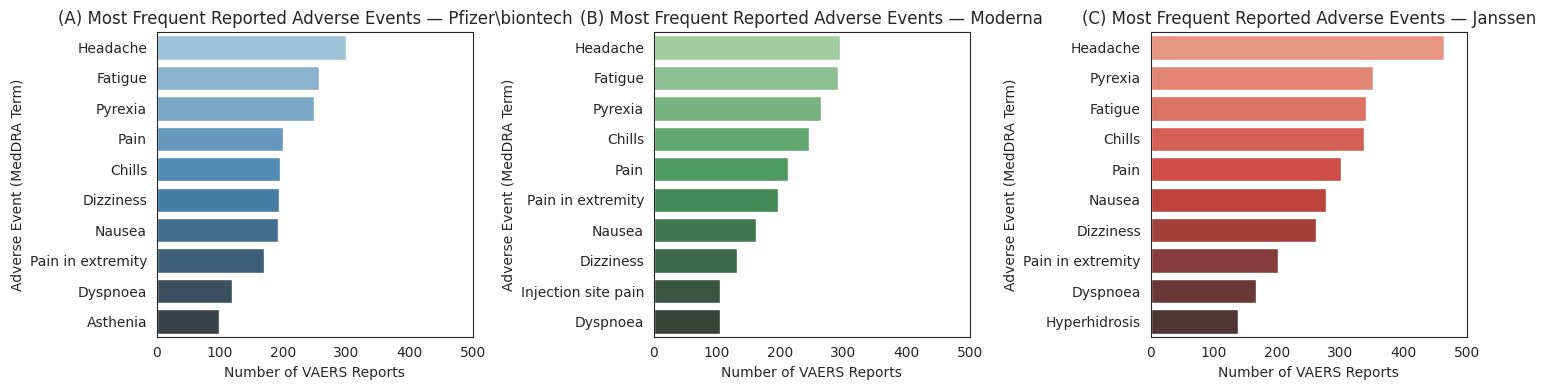

In [41]:
plot_top10_symptoms_per_manufacturer_panels(
    top10_by_manu,
    manufacturers,                      # e.g. ["PFIZER", "MODERNA", "JANSSEN"]
    is_first_reported=False,
    palettes=("Blues_d", "Greens_d", "Reds_d"),
    figsize=(15, 4),
    xlim=(0, 500),
)

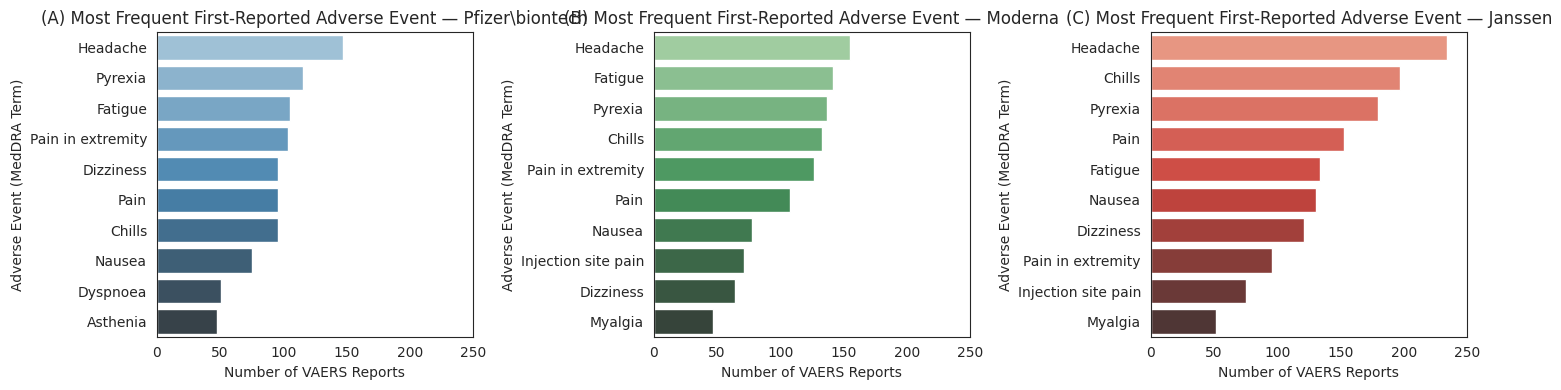

In [42]:
plot_top10_symptoms_per_manufacturer_panels(
    top10_1st_by_manu,
    manufacturers,                      # e.g. ["PFIZER", "MODERNA", "JANSSEN"]
    is_first_reported=True,
    palettes=("Blues_d", "Greens_d", "Reds_d"),
    figsize=(15, 4),
    xlim=(0, 250),
)

Heatmap: Pfizer\biontech


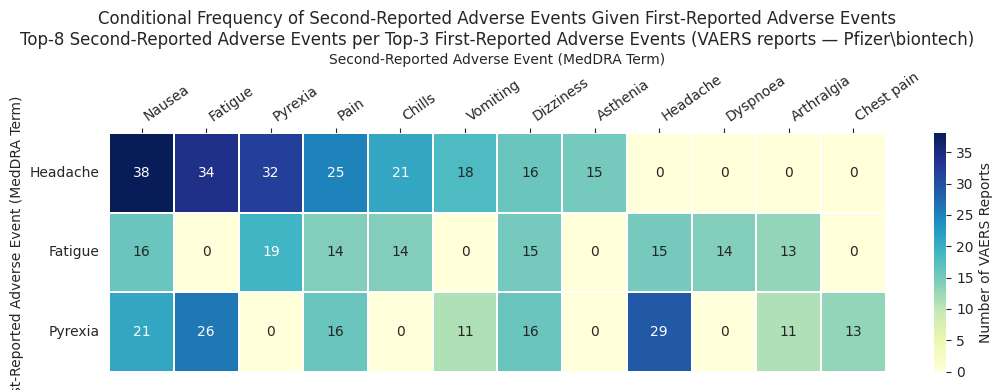

Heatmap: Moderna


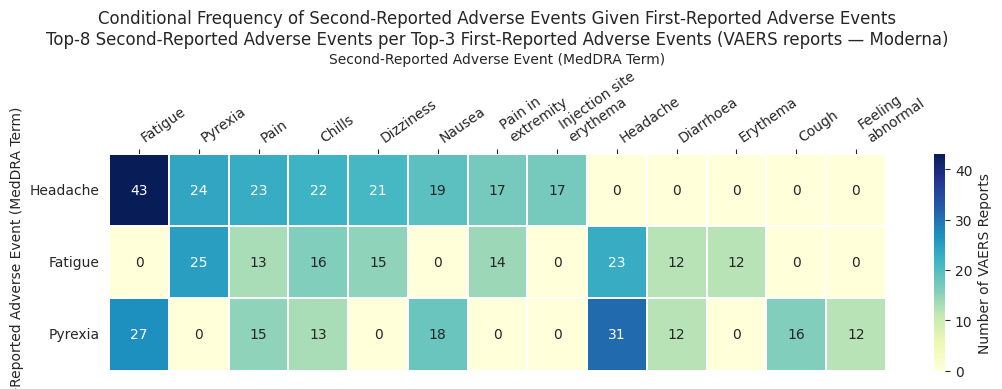

Heatmap: Janssen


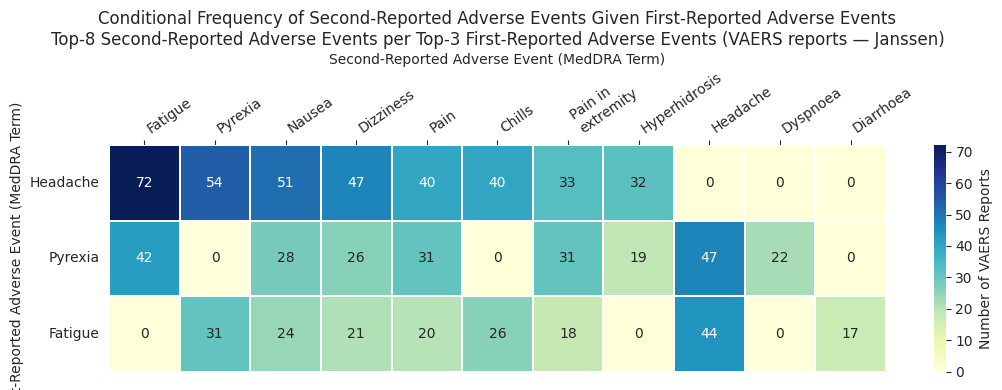

Heatmap: Overall


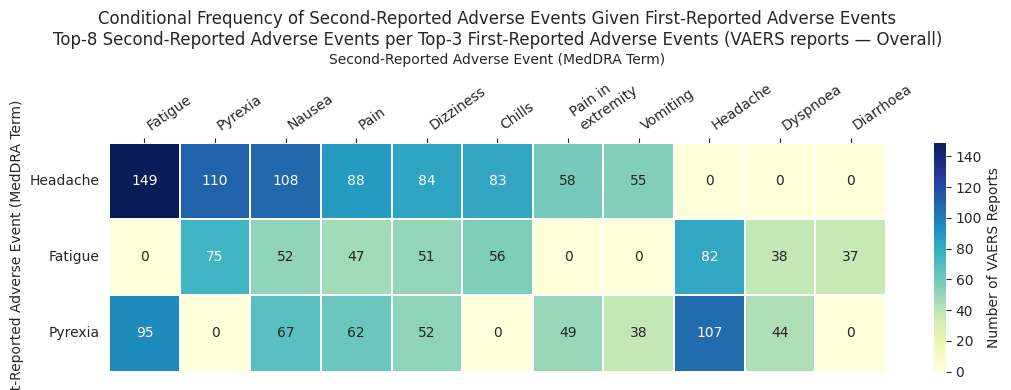

In [43]:
# Analyze and plot heatmap (ACL-targeted labeling)
def plot_top_after_symptom_heatmap(
    df,
    top_first_symptoms,
    manufacturer=None,
    top_n_second=5,
    dataset_name="VAERS",
    first_event_definition="First-Reported Adverse Event",
    second_event_definition="Second-Reported Adverse Event",
):
    """
    Heatmap: counts of (first_event, second_event) co-occurrences in reports,
    restricted to top first events and top second events per first event.
    """

    import textwrap
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns

    heatmap_data = pd.DataFrame()

    for first_symptom in top_first_symptoms:
        # Get the top N second events for the current first event
        top_second_symptoms = get_top_after_symptoms(df, first_symptom, manufacturer, top_n_second)

        for second_symptom, count in top_second_symptoms:
            heatmap_data.loc[first_symptom, second_symptom] = count

    heatmap_data = heatmap_data.fillna(0)

    # Manufacturer label for plot text
    manu_label = manufacturer if manufacturer else "Overall"
    cohort_label = f"{dataset_name} reports — {manu_label}"

    # Plot heatmap
    plt.figure(figsize=(11, 4))
    ax = sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".0f",
        cmap="YlGnBu",
        cbar_kws={"label": f"Number of {dataset_name} Reports"},
        linewidths=0.3,
        linecolor="white",
    )

    # Put x ticks on top (as you had)
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()

    # ACL-style axis labels
    ax.set_xlabel(f"{second_event_definition} (MedDRA Term)")
    ax.set_ylabel(f"{first_event_definition} (MedDRA Term)")

    # Wrap long MedDRA terms on x-axis
    labels = [textwrap.fill(label.get_text(), 14) for label in ax.get_xticklabels()]
    ax.set_xticklabels(labels, rotation=35, ha="left")

    # Cleaner y-axis labels (also wrapped if needed)
    ylabels = [textwrap.fill(label.get_text(), 22) for label in ax.get_yticklabels()]
    ax.set_yticklabels(ylabels, rotation=0)

    # ACL-style title (method + cohort)
    plt.title(
        f"Conditional Frequency of {second_event_definition}s Given {first_event_definition}s\n"
        f"Top-{top_n_second} {second_event_definition}s per Top-{len(top_first_symptoms)} {first_event_definition}s ({cohort_label})"
    )
    
    plt.tight_layout()
    plt.show()


# ---- Usage ----
n_first = 3
n_second = 8
manufacturers = [PFIZER, MODERNA, JANSSEN, None]  # None for overall

for manu in manufacturers:
    manu_label = manu if manu else "Overall"
    print(f"Heatmap: {manu_label}")

    top_first_symptoms = get_top_frequent_symptoms(temporal_data, n=n_first, manufacturer=manu)

    plot_top_after_symptom_heatmap(
        temporal_data,
        top_first_symptoms,
        manufacturer=manu,
        top_n_second=n_second,
        dataset_name="VAERS",
        first_event_definition="First-Reported Adverse Event",
        second_event_definition="Second-Reported Adverse Event",
    )
    

In [44]:
n_first = 5
n_second = 10
manufacturers = [PFIZER, MODERNA, JANSSEN, None]

In [45]:
data.iloc[:, :5]

,vaers_id,vax_type,vax_manu,age_yrs,sex
0,1420769.0,COVID19,Pfizer\biontech,59.0,F
1,1527339.0,COVID19,Pfizer\biontech,44.0,M
2,1711389.0,COVID19,Pfizer\biontech,NaN,F
3,1021935.0,COVID19,Pfizer\biontech,68.0,M
4,2749020.0,COVID19,Pfizer\biontech,11.0,M
...,...,...,...,...,...
5995,1200536.0,COVID19,Janssen,56.0,F
5996,1164708.0,COVID19,Janssen,41.0,F
5997,1189456.0,COVID19,Janssen,NaN,F
5998,1465774.0,COVID19,Janssen,33.0,F


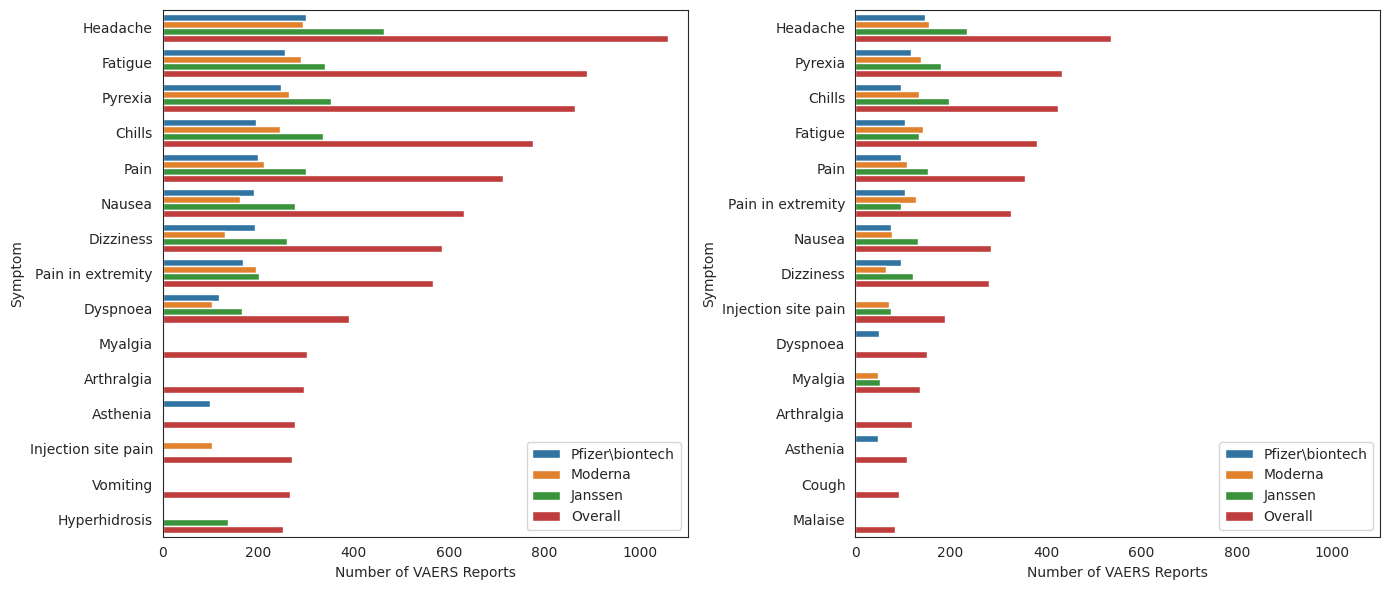

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6)) #, sharey=True)

plot_top10_symptoms_consolidated_ax(
    overall_df=overall_df,
    manufacturers=[PFIZER, MODERNA, JANSSEN],
    overall_col="Overall",
    ax=axes[0],
)

plot_top10_symptoms_consolidated_ax(
    overall_df=overall_1st_df,
    manufacturers=[PFIZER, MODERNA, JANSSEN],
    overall_col="Overall",
    ax=axes[1],
)
# axes[0].set_title("Reported Adverse Events", fontsize=10)
# axes[1].set_title("First-Reported Adverse Events", fontsize=10)

plt.tight_layout()
plt.savefig("top_adverse_events_acl.pdf", bbox_inches="tight")

plt.show()

In [47]:
from matplotlib.colors import LinearSegmentedColormap


def _plot_top_pair_heatmap(
    df,
    top_first_symptoms,
    get_top_pairs_fn,
    manufacturer=None,
    top_n_second=5,
    dataset_name="VAERS",
    first_event_definition="First-Reported Adverse Event",
    second_event_definition="Second-Reported Adverse Event",
    figsize=(3, 2.5),
    cmap="YlGnBu",
    x_wrap=14,
    y_wrap=14,
    # vmin=0,
    # vmax=350,
    save_path=None,
    dpi=300,
):
    import textwrap
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    from matplotlib.colors import PowerNorm, LogNorm


    heatmap_data = pd.DataFrame()

    for first_symptom in top_first_symptoms:
        top_second_symptoms = get_top_pairs_fn(df, first_symptom, manufacturer, top_n_second)
        for second_symptom, count in top_second_symptoms:
            heatmap_data.loc[first_symptom, second_symptom] = count

    heatmap_data = heatmap_data.fillna(0)
    heatmap_data = heatmap_data.iloc[:, :len(top_first_symptoms)]

    manu_label = manufacturer if manufacturer else "Overall"
    cohort_label = f"{dataset_name} reports — {manu_label}"

    fig, ax = plt.subplots(figsize=figsize)


    # cmap = sns.cubehelix_palette(start=2, rot=1.2, dark=0.35, light=0.75, as_cmap=True)
    cmap = LinearSegmentedColormap.from_list("custom", ["#a286b9", "#e0a6ac", "#f0bc41"])

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".0f",
        cmap=cmap,
        # vmin=vmin,
        # vmax=vmax,
        # cbar_kws={"label": f"Number of {dataset_name} Reports"},
        # norm=PowerNorm(gamma=0.4, vmin=0, vmax=heatmap_data.values.max()),

        # norm=LogNorm(vmin=1, vmax=heatmap_data.values.max()),
        linewidths=0.3,
        linecolor="white",
        ax=ax,
        annot_kws={"size": 9, "color": "white"},

    )
    ### added 
    plt.rcParams["font.family"] = "serif"   # set once, top of notebook
    ax.tick_params(axis="both", which="both", length=0)

    xlabels = [textwrap.fill(t.get_text(), x_wrap) for t in ax.get_xticklabels()]
    ax.set_xticklabels(xlabels, rotation=40, ha="left", fontsize = 10)

    ylabels = [textwrap.fill(t.get_text(), y_wrap) for t in ax.get_yticklabels()]
    ax.set_yticklabels(ylabels, rotation=0, fontsize=10)

    ax.set_xlabel("Earlier symptom", fontsize=11, labelpad=10)
    ax.set_ylabel("Later symptom", fontsize=11, labelpad=10)

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=9)

    ###  added

    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()

    # ax.set_xlabel(f"Symptom 2")
    # ax.set_ylabel(f"Symptom 1")

    # xlabels = [textwrap.fill(t.get_text(), x_wrap) for t in ax.get_xticklabels()]
    # ax.set_xticklabels(xlabels, rotation=40, ha="left")

    # ylabels = [textwrap.fill(t.get_text(), y_wrap) for t in ax.get_yticklabels()]
    # ax.set_yticklabels(ylabels, rotation=0)

    # ax.set_title(
    #     f"Conditional Frequency of {second_event_definition}s Given {first_event_definition}s\n",
    #     f"Top-{top_n_second} {second_event_definition}s per Top-{len(top_first_symptoms)} ",
    #     f"{first_event_definition}s ({cohort_label})",
    # )

    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight", dpi=dpi)
    # save plt as pdf
    plt.savefig(f"claude_craft_symptom_heatmap_{manu_label}.pdf", format="pdf", bbox_inches="tight")
    plt.show()
    return heatmap_data  # handy if you want to inspect/export later


def plot_top_second_symptom_heatmap(
    df,
    top_first_symptoms,
    manufacturer=None,
    top_n_second=5,
    dataset_name="VAERS",
    first_event_definition="First-Reported Adverse Event",
    second_event_definition="Second-Reported Adverse Event",
    **kwargs,
):
    return _plot_top_pair_heatmap(
        df=df,
        top_first_symptoms=top_first_symptoms,
        get_top_pairs_fn=get_top_second_symptoms,
        manufacturer=manufacturer,
        top_n_second=top_n_second,
        dataset_name=dataset_name,
        first_event_definition=first_event_definition,
        second_event_definition=second_event_definition,
        **kwargs,
    )

def plot_top_after_symptom_heatmap(
    df,
    top_first_symptoms,
    manufacturer=None,
    top_n_second=5,
    dataset_name="VAERS",
    first_event_definition="First-Reported Adverse Event",
    second_event_definition="Second-Reported Adverse Event",
    **kwargs,
):
    return _plot_top_pair_heatmap(
        df=df,
        top_first_symptoms=top_first_symptoms,
        get_top_pairs_fn=get_top_after_symptoms,
        manufacturer=manufacturer,
        top_n_second=top_n_second,
        dataset_name=dataset_name,
        first_event_definition=first_event_definition,
        second_event_definition=second_event_definition,
        **kwargs,
    )

def plot_top_cooccuring_symptom_heatmap(
    df,
    top_first_symptoms,
    manufacturer=None,
    top_n_second=5,
    dataset_name="VAERS",
    first_event_definition="First-Reported Adverse Event",
    second_event_definition="Second-Reported Adverse Event",
    **kwargs,
):
    return _plot_top_pair_heatmap(
        df=df,
        top_first_symptoms=top_first_symptoms,
        get_top_pairs_fn=get_top_coocurring_symptoms,
        manufacturer=manufacturer,
        top_n_second=top_n_second,
        dataset_name=dataset_name,
        first_event_definition=first_event_definition,
        second_event_definition=second_event_definition,
        **kwargs,
    )


## get model results ready

In [48]:
def remove_none_symptoms(llm_result):
    llm_result_lst = ast.literal_eval(llm_result)
    # print(llm_result_lst)
    # print(type(llm_result_lst))
    temporal_list = []
    try:
        if any(value in ["none", ["none"]] for value in llm_result_lst[-1].values()):
            llm_result_lst = llm_result_lst[:-1]
        for temp_group in llm_result_lst:
            temporal_list.append(list(temp_group.keys()))
        return temporal_list
    except:
        print('Error occurred while parsing llm_result_final')

In [49]:
df_model = pd.read_csv("claude_plain_results_with_temporal_final.csv")
# df_model.head()
# gold_source = pd.read_csv("o4mini_annotation_final.csv")
# write a code to get vax_manu value from data and merge it into df_model based on vaers_id
df_model = df_model.merge(data[['vaers_id', 'vax_manu']], on='vaers_id', how='left')
df_model.head()
# get llm_result_final from df_model based on llm_result_formatted and if final_corrected_version has anything, adopt that as llm_result_final
def get_final_llm_result(row):
    if isinstance(row['final_corrected_version'], list) and len(row['final_corrected_version']) > 0:
        return row['final_corrected_version']
    else:
        return row['llm_result_formatted']
df_model['llm_result_final'] = df_model.apply(get_final_llm_result, axis=1)
# eg = remove_none_symptoms(df_model['llm_result_final'][0])
# eg
df_model['indexed_symptoms'] = df_model['llm_result_final'].apply(remove_none_symptoms)

In [50]:
df_model.head()

,vaers_id,symptom_text,symptom_list,llm_result,llm_result_formatted,final_corrected_version,final_result,no_temporal_info,new_llm_result,final_result_cleaned,vax_manu,llm_result_final,indexed_symptoms
0,1420769,"About 4-5 days after my second dose, I began h...","['Chest discomfort', 'Chest pain', 'Electrocar...","[ \n { \n ""Chest pain"": [""non stop chest...","[\n {\n ""Chest pain"": [\n ""non stop c...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Chest pain"": [\n ""non stop c...",Pfizer\biontech,"[\n {\n ""Chest pain"": [\n ""non stop c...","[[Chest pain], [Electrocardiogram abnormal, Ch..."
1,1831772,"Muscle pain, headache, nausea. Muscle pain ins...","['Headache', 'Immediate post-injection reactio...","[\n {\n ""Headache"": [""none""],\n ""Immedi...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...","[\n {\n ""Myalgia"": [\n ""Muscle pain""\...",0,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Myalgia"": [\n ""Muscle pain i...",Janssen,"[\n {\n ""Myalgia"": [\n ""Muscle pain""\...","[[Myalgia], [Headache, Nausea]]"
2,1021935,back pain/soreness in his lower back/had bad l...,"['Arthralgia', 'Back pain', 'Nausea', 'Pain in...","[\n {\n ""Vaccination site pain"": [""injecti...","[\n {\n ""Vaccination site pain"": [\n ...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Vaccination site pain"": [\n ...",Pfizer\biontech,"[\n {\n ""Vaccination site pain"": [\n ...","[[Vaccination site pain, Pain in extremity, Ar..."
3,2749020,The above vaccines administered without incide...,"['Dizziness', 'Fall', 'Fatigue', 'Head injury'...","[\n {\n ""Syncope"": [""patient fainted""],\n ...","[\n {\n ""Syncope"": [\n ""patient faint...",NaN,1,False,"{'attempts': [{'raw_gen': '```json\n[\n {""Syn...","[\n {\n ""Syncope"": [\n ""patient faint...",Pfizer\biontech,"[\n {\n ""Syncope"": [\n ""patient faint...","[[Syncope, Fall, Head injury], [Headache, Dizz..."
4,940509,"about 4 hrs after vaccination ee had ""tunnel ...","['Dizziness', 'Faeces soft', 'Fatigue', 'Flatu...","[\n {\n ""Tunnel vision"": [""tunnel vision""]...","[\n {\n ""Tunnel vision"": [\n ""tunnel ...",NaN,1,False,{'attempts': [{'raw_gen': '```json\n[\n {\n ...,"[\n {\n ""Tunnel vision"": [\n ""tunnel ...",Pfizer\biontech,"[\n {\n ""Tunnel vision"": [\n ""tunnel ...","[[Tunnel vision, Dizziness, Nausea, Flatulence..."


Heatmap: Pfizer\biontech


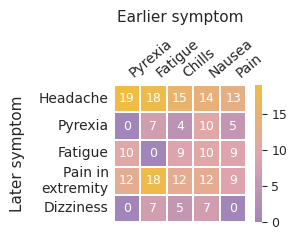

Heatmap: Moderna


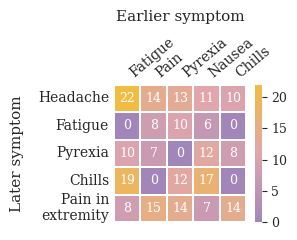

Heatmap: Janssen


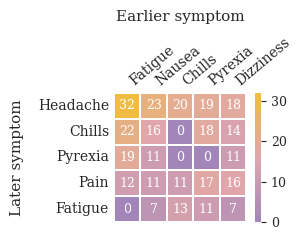

Heatmap: Overall


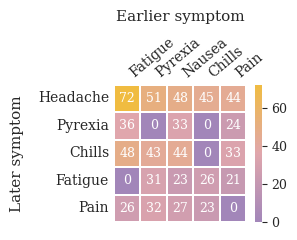

In [51]:
# first vs second

for manu in manufacturers:
    manu_label = manu if manu else "Overall"
    print(f"Heatmap: {manu_label}")

    top_first_symptoms = get_top_first_symptoms(df_model, n=n_first, manufacturer=manu)

    data = plot_top_second_symptom_heatmap(
        temporal_data,
        top_first_symptoms,
        manufacturer=manu,
        top_n_second=n_second,
        dataset_name="VAERS",
        first_event_definition="First-Reported Adverse Event",
        second_event_definition="Second-Reported Adverse Event",
    )

Heatmap: Pfizer\biontech


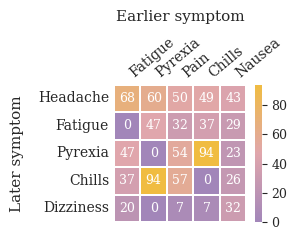

Heatmap: Moderna


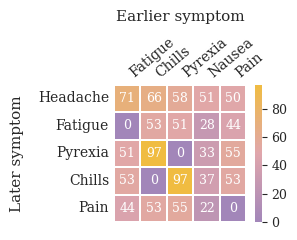

Heatmap: Janssen


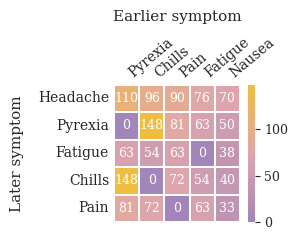

Heatmap: Overall


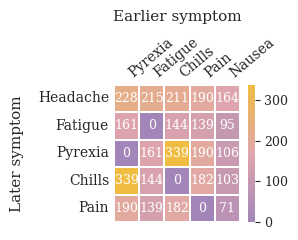

In [52]:
# frequent co-occurring symptoms (regardless of order)
for manu in manufacturers:
    manu_label = manu if manu else "Overall"
    print(f"Heatmap: {manu_label}")

    top_first_symptoms = get_top_frequent_symptoms(df_model, n=n_first, manufacturer=manu)

    plot_top_cooccuring_symptom_heatmap(
        df_model,
        top_first_symptoms,
        manufacturer=manu,
        top_n_second=n_second,
        dataset_name="VAERS",
        first_event_definition="First-Reported Adverse Event",
        second_event_definition="Second-Reported Adverse Event",
    )

Heatmap: Pfizer\biontech


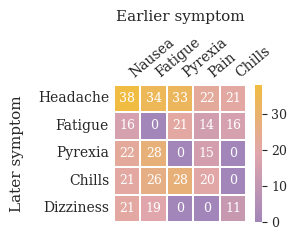

Heatmap: Moderna


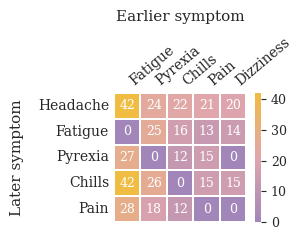

Heatmap: Janssen


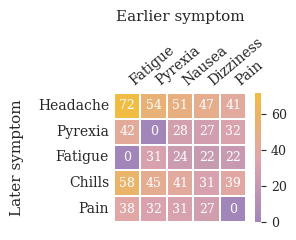

Heatmap: Overall


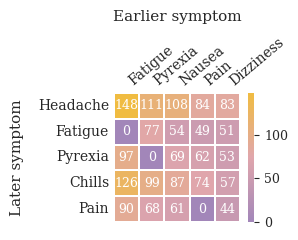

In [53]:
# before vs after 
for manu in manufacturers:
    manu_label = manu if manu else "Overall"
    print(f"Heatmap: {manu_label}")

    top_first_symptoms = get_top_frequent_symptoms(df_model, n=n_first, manufacturer=manu)

    plot_top_after_symptom_heatmap(
        df_model,
        top_first_symptoms,
        manufacturer=manu,
        top_n_second=n_second,
        dataset_name="VAERS",
        first_event_definition="First-Reported Adverse Event",
        second_event_definition="Second-Reported Adverse Event",
    )
    

### (a) Most Frequent Second-Reported Adverse Events Conditioned on First-Reported Events  

Heatmap: Pfizer\biontech


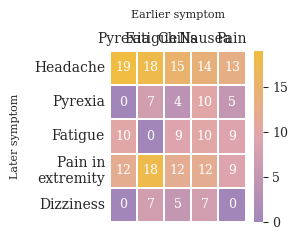

Heatmap: Moderna


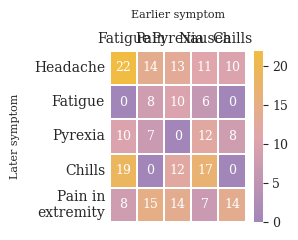

Heatmap: Janssen


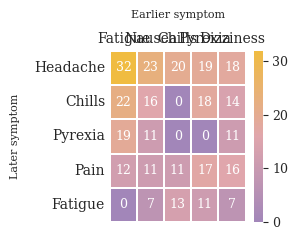

Heatmap: Overall


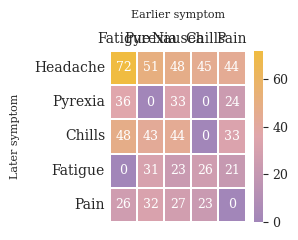

In [ ]:
for manu in manufacturers:
    manu_label = manu if manu else "Overall"
    print(f"Heatmap: {manu_label}")

    top_first_symptoms = get_top_first_symptoms(temporal_data, n=n_first, manufacturer=manu)

    data = plot_top_second_symptom_heatmap(
        temporal_data,
        top_first_symptoms,
        manufacturer=manu,
        top_n_second=n_second,
        dataset_name="VAERS",
        first_event_definition="First-Reported Adverse Event",
        second_event_definition="Second-Reported Adverse Event",
    )

### (b) Most Frequent Co-Occurring Adverse Events with Common Primary Events  

Heatmap: Pfizer\biontech


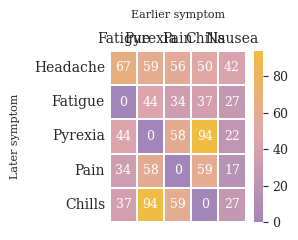

Heatmap: Moderna


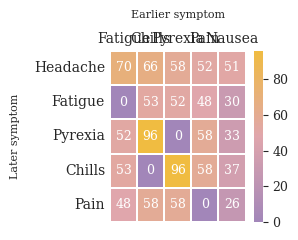

Heatmap: Janssen


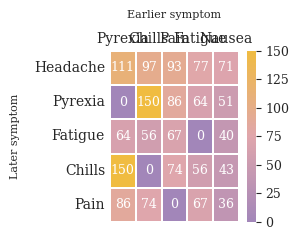

Heatmap: Overall


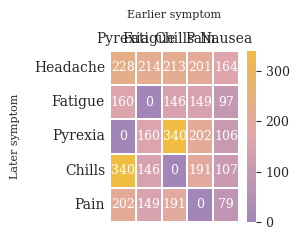

In [ ]:
for manu in manufacturers:
    manu_label = manu if manu else "Overall"
    print(f"Heatmap: {manu_label}")

    top_first_symptoms = get_top_frequent_symptoms(temporal_data, n=n_first, manufacturer=manu)

    plot_top_cooccuring_symptom_heatmap(
        temporal_data,
        top_first_symptoms,
        manufacturer=manu,
        top_n_second=n_second,
        dataset_name="VAERS",
        first_event_definition="First-Reported Adverse Event",
        second_event_definition="Second-Reported Adverse Event",
    )


### (c) Adverse Events Most Frequently Reported After Common Initial Events

Heatmap: Pfizer\biontech


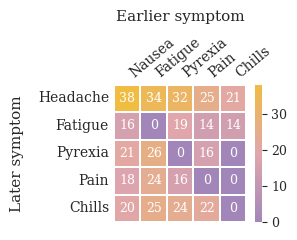

Heatmap: Moderna


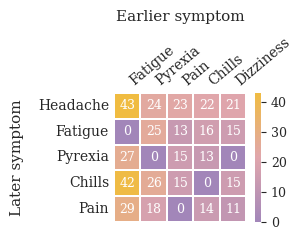

Heatmap: Janssen


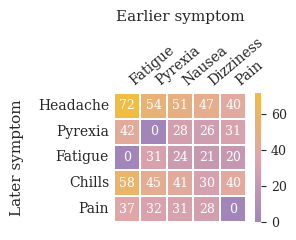

Heatmap: Overall


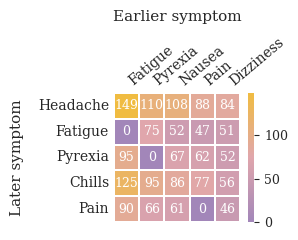

In [ ]:
for manu in manufacturers:
    manu_label = manu if manu else "Overall"
    print(f"Heatmap: {manu_label}")

    top_first_symptoms = get_top_frequent_symptoms(temporal_data, n=n_first, manufacturer=manu)

    plot_top_after_symptom_heatmap(
        temporal_data,
        top_first_symptoms,
        manufacturer=manu,
        top_n_second=n_second,
        dataset_name="VAERS",
        first_event_definition="First-Reported Adverse Event",
        second_event_definition="Secon
        " \
        "
        
        
        
        
        
        
        
        
        .0
        
        .0.df=.00
        33213211231.0.0.0
        .00.0..0
        .0
        .
        .0
        0.0.df=.0
        00
        0.0..0
        .0.0.0.0.0
        000..00..0.0
        .0
        .013256787d-Reported Adverse Event",
    )